In [2]:
import csv
from collections import Counter
from pathlib import Path

CSV_FILE = Path("../dataset/PQD-16c-Data/PQD-16C-Data.csv")

counts = Counter()

with open(CSV_FILE, "r", newline="", encoding="utf-8") as file:
    reader = csv.reader(file)

    # Skip header
    next(reader)

    # Read only the first column
    for row in reader:
        if row:
            label = row[0].strip()
            counts[label] += 1


print("PQD-16C DATASET CLASS DISTRIBUTION")
print("=" * 45)
print()

for label, count in sorted(counts.items()):
    print(f"{label}: {count}")

print()
print("=" * 45)
print(f"Total samples: {sum(counts.values())}")
print(f"Total classes: {len(counts)}")

PQD-16C DATASET CLASS DISTRIBUTION

Flicker: 100
Flicker+Harmonics: 100
Flicker+Sag: 100
Flicker+Swell: 100
Harmonics: 100
Impulsive Transient: 100
Interruption: 100
Interruption+Harmonics: 100
Normal: 100
Notch: 100
Oscillatory transient: 100
Sag: 100
Sag+Harmonics: 100
Spike: 100
Swell: 100
Swell+Harmonics: 100

Total samples: 1600
Total classes: 16


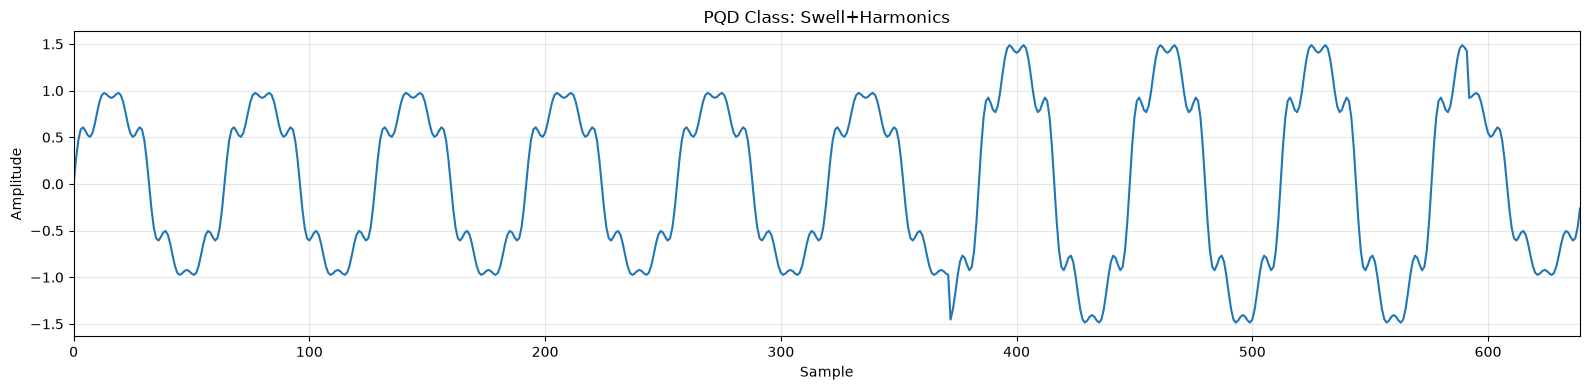

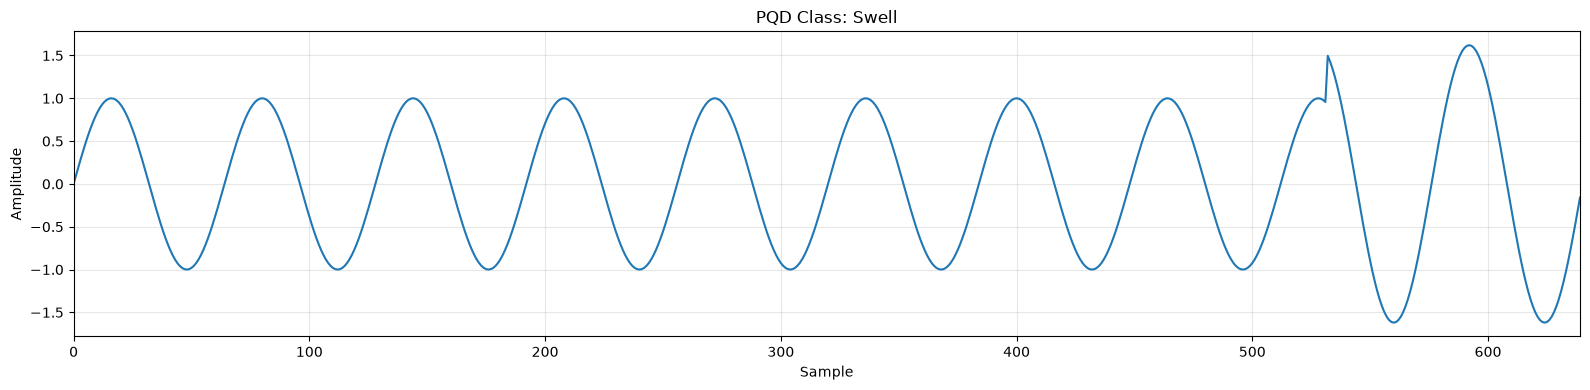

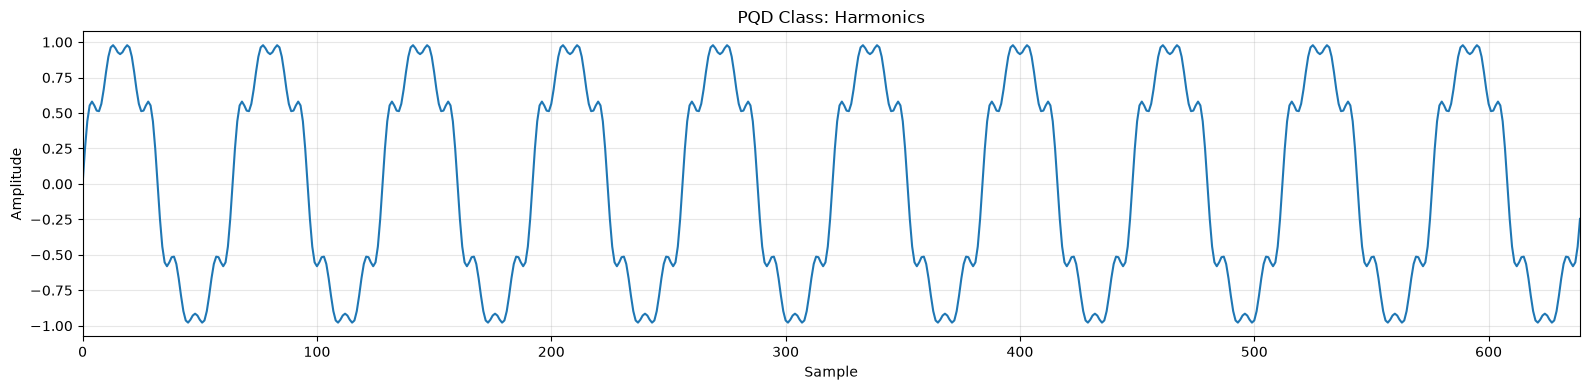

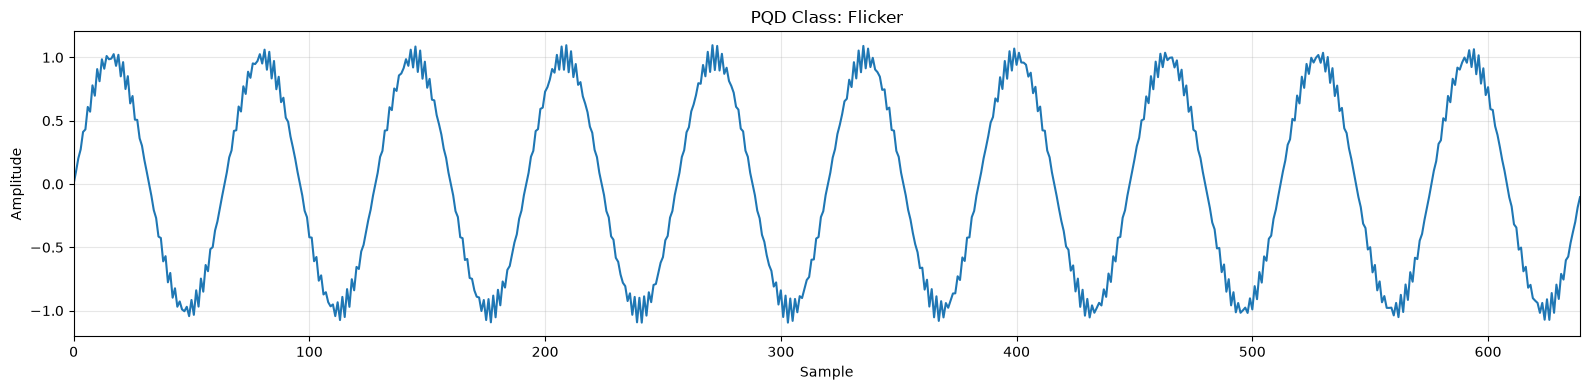

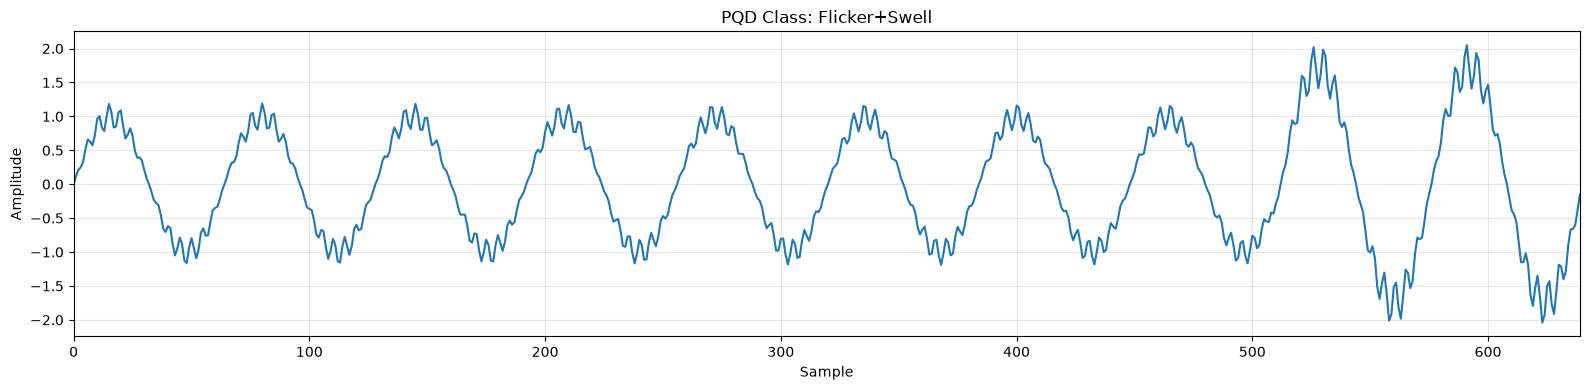

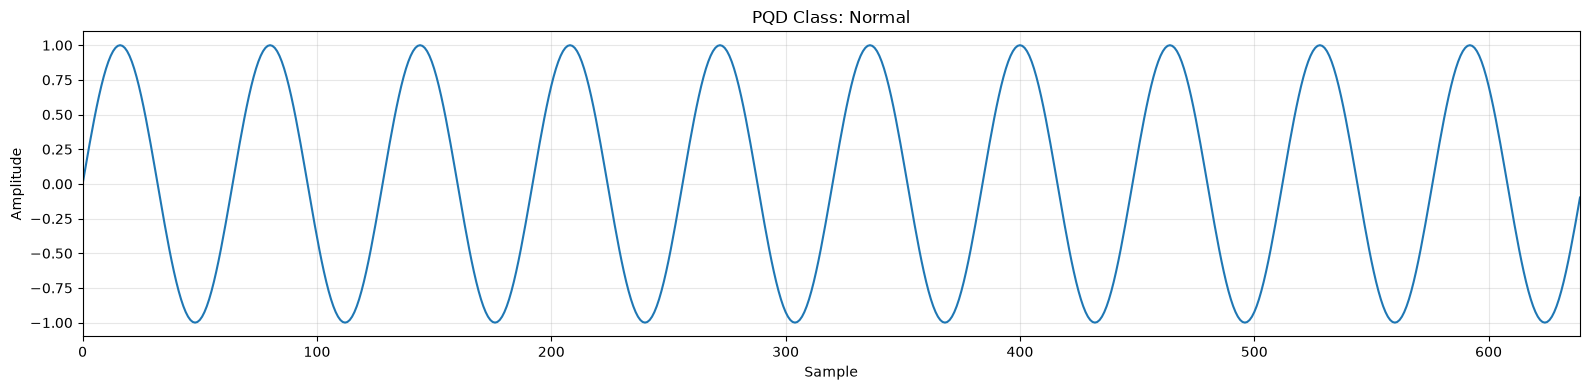

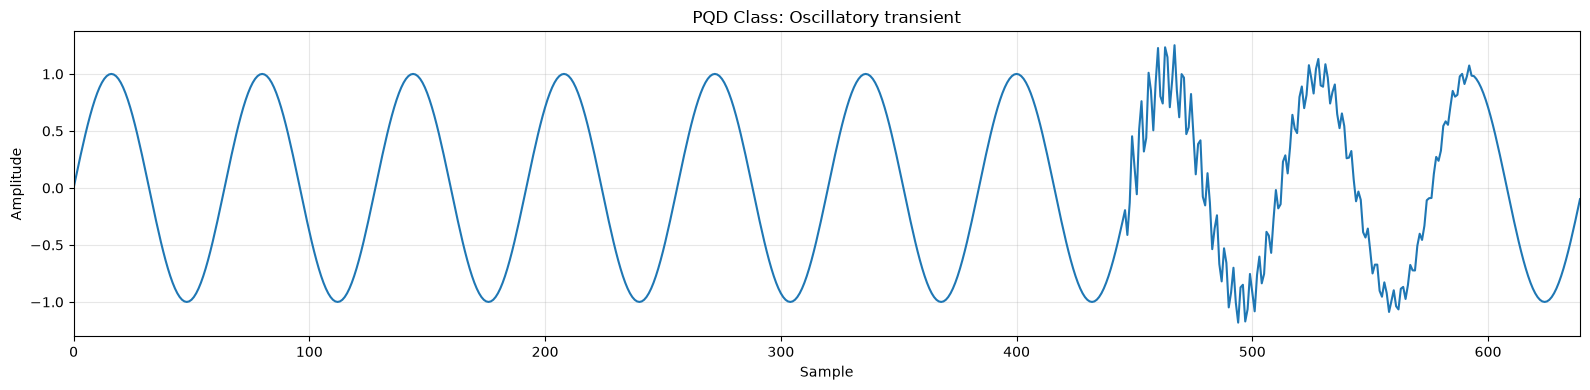

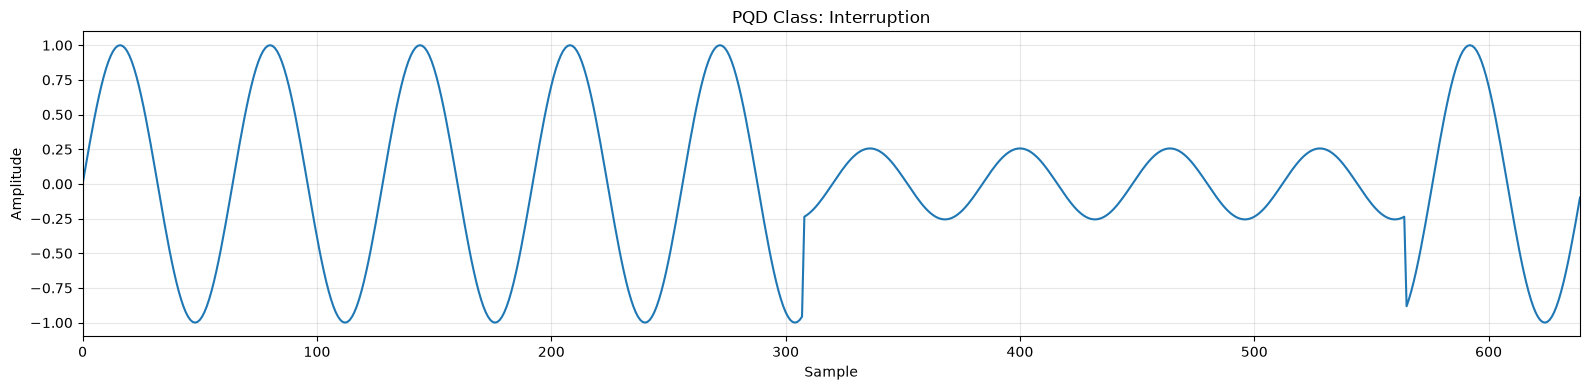

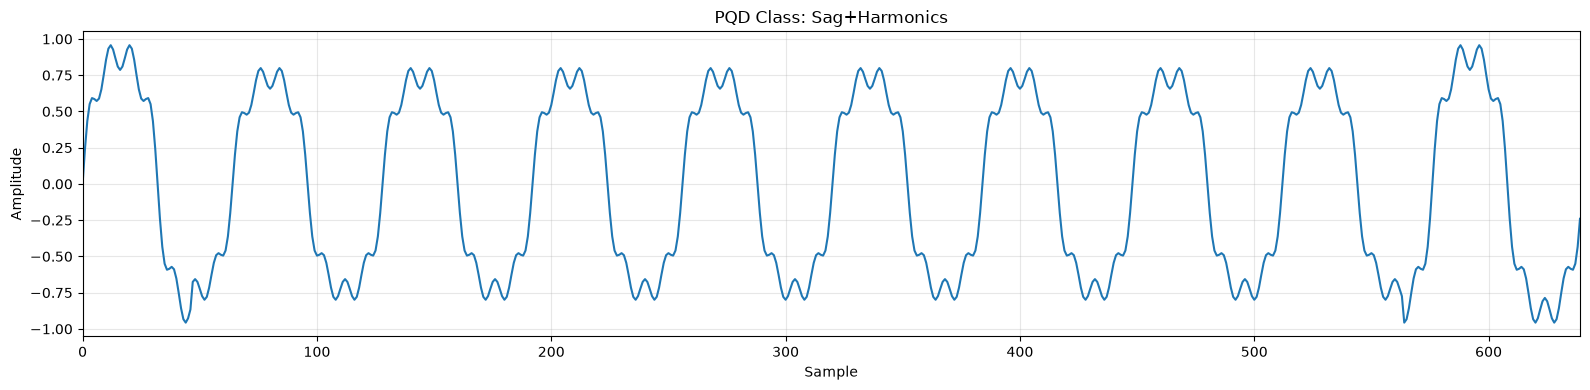

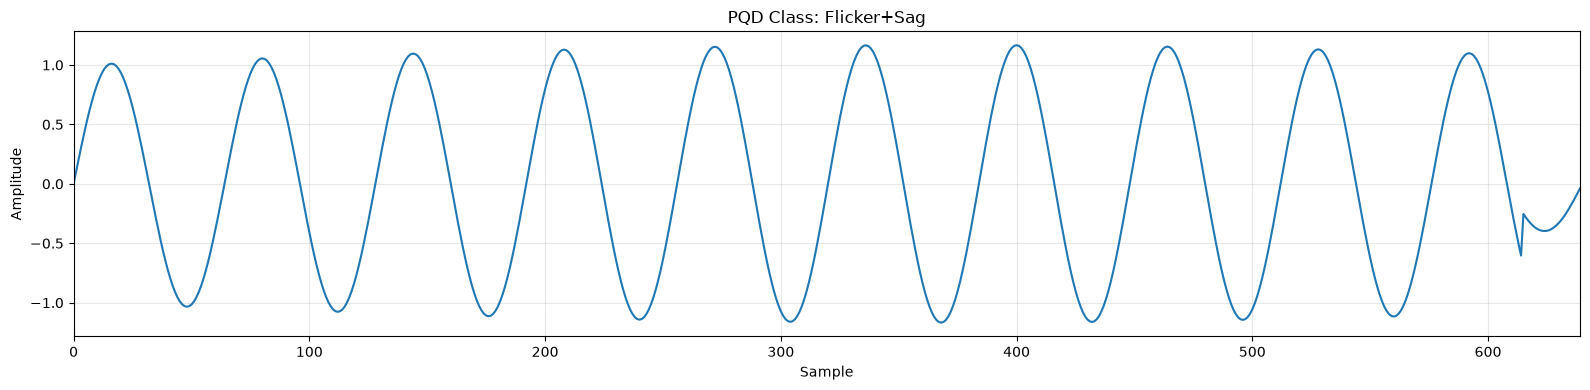

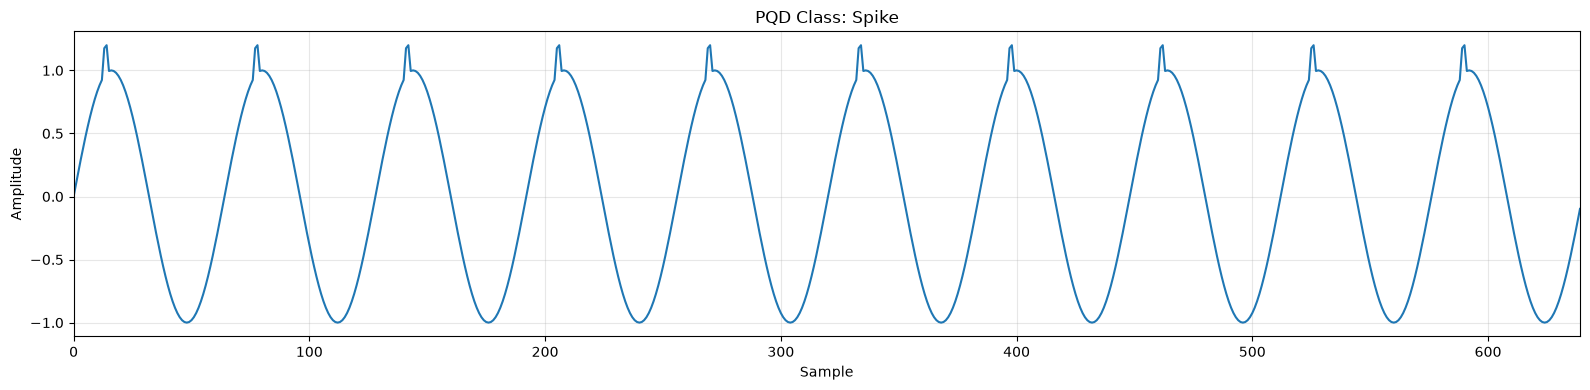

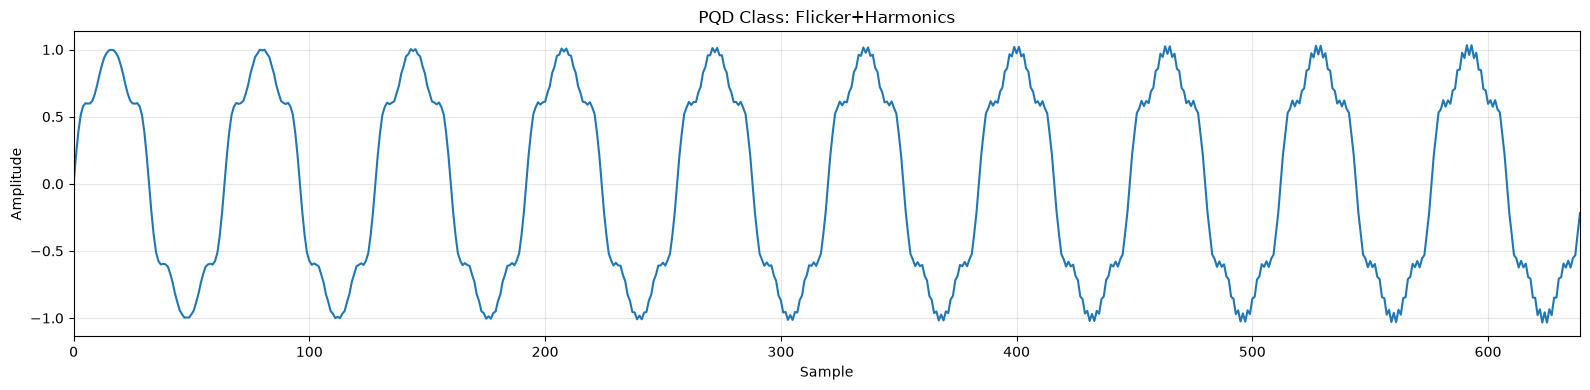

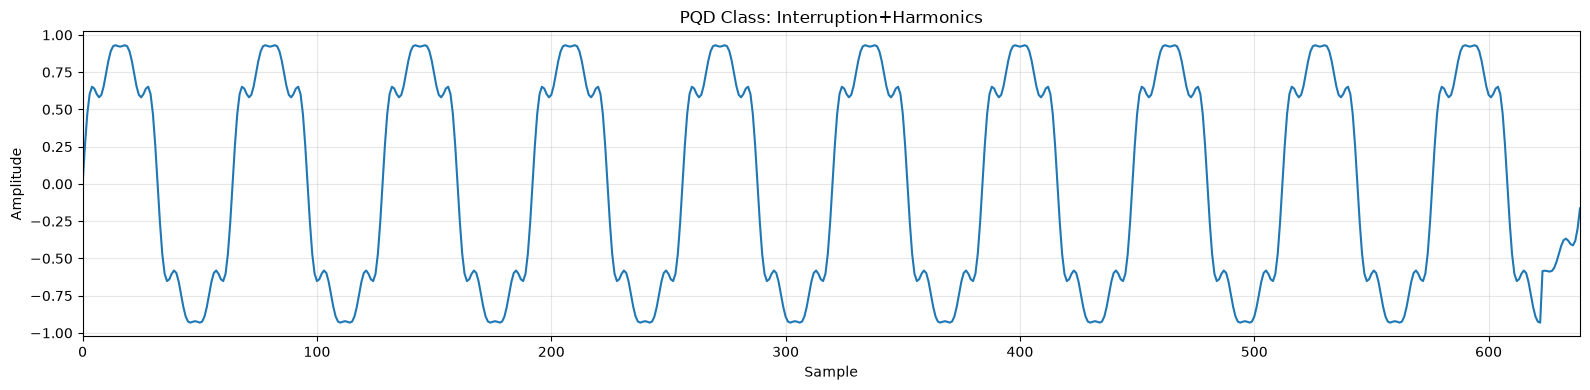

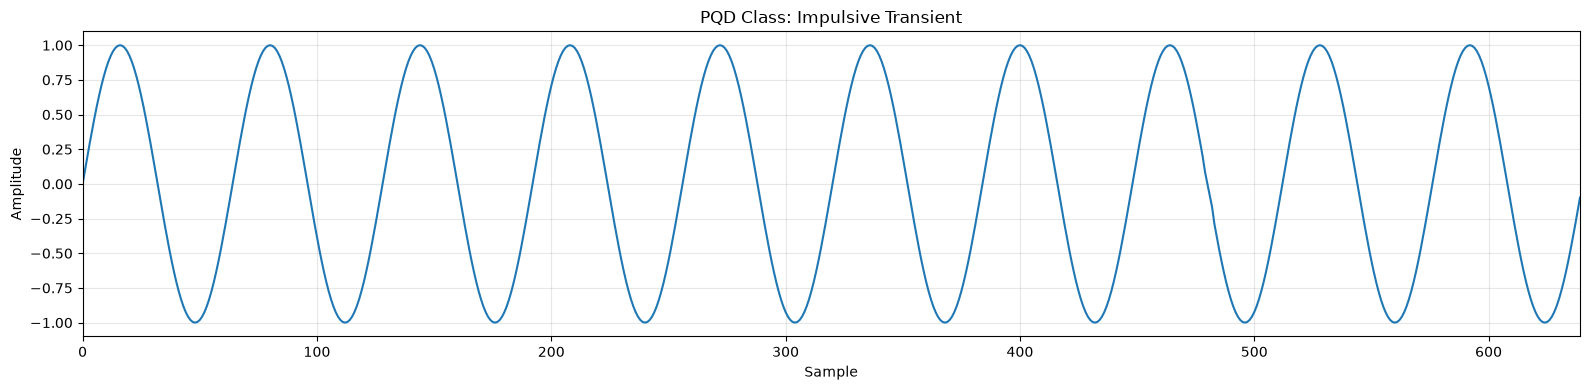

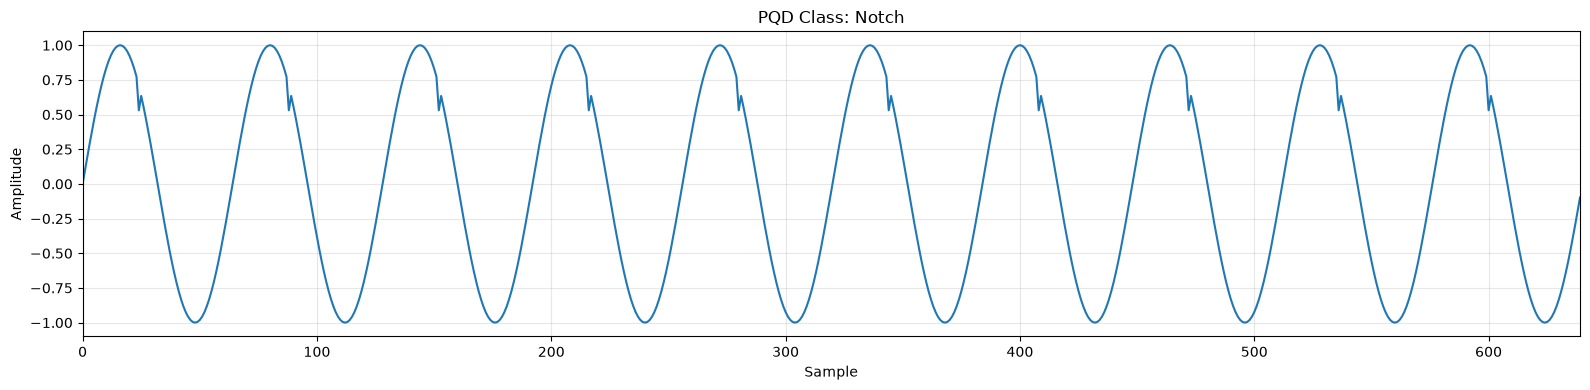

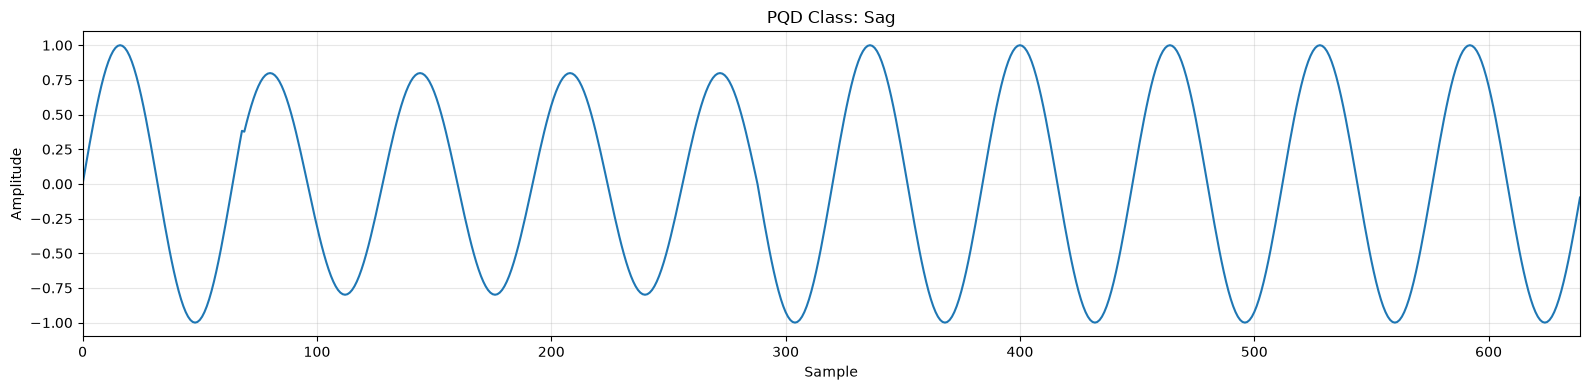

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# --------------------------------------------------
# Configuration
# --------------------------------------------------

CSV_FILE = Path("../dataset/PQD-16c-Data/PQD-16C-Data.csv")

# --------------------------------------------------
# Load dataset
# --------------------------------------------------

df = pd.read_csv(CSV_FILE)

label_column = df.columns[0]
signal_columns = df.columns[1:]

# --------------------------------------------------
# Plot one random waveform from each class
# --------------------------------------------------

for label in df[label_column].unique():

    # Get all samples belonging to this class
    class_samples = df[df[label_column] == label]

    # Select one random waveform
    row = class_samples.sample(n=1).iloc[0]

    # Extract the 640 signal samples
    signal = row[signal_columns].astype(float).values

    # --------------------------------------------------
    # Plot
    # --------------------------------------------------

    plt.figure(figsize=(16, 4))

    plt.plot(signal)

    plt.title(f"PQD Class: {label}")
    plt.xlabel("Sample")
    plt.ylabel("Amplitude")
    plt.xlim(0, 639)

    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    plt.show()

In [6]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn

from pathlib import Path
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


# ============================================================
# CONFIGURATION
# ============================================================

CSV_FILE = Path("../dataset/PQD-16c-Data/PQD-16C-Data.csv")

RANDOM_STATE = 42

BATCH_SIZE = 32
EPOCHS = 100

LEARNING_RATE = 0.0001

HIDDEN_SIZE = 64
NUM_LAYERS = 2

# ============================================================
# DEVICE
# ============================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 60)
print("DEVICE")
print("=" * 60)
print(device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print()


# ============================================================
# LOAD DATASET
# ============================================================

print("=" * 60)
print("LOADING DATASET")
print("=" * 60)

df = pd.read_csv(CSV_FILE)

print("Dataset shape:", df.shape)

# First column = labels
labels = df.iloc[:, 0].values

# Remaining 640 columns = waveform
signals = df.iloc[:, 1:].values.astype(np.float32)

print("Signals shape:", signals.shape)
print("Labels shape :", labels.shape)

print()


# ============================================================
# ENCODE LABELS
# ============================================================

label_encoder = LabelEncoder()

y = label_encoder.fit_transform(labels)

NUM_CLASSES = len(label_encoder.classes_)

print("=" * 60)
print("CLASSES")
print("=" * 60)

for i, class_name in enumerate(label_encoder.classes_):
    print(f"{i:2d} -> {class_name}")

print()

print("Number of classes:", NUM_CLASSES)


# ============================================================
# TRAIN / VALIDATION / TEST SPLIT
# ============================================================

# First:
# 80% development data
# 20% test data

X_dev, X_test, y_dev, y_test = train_test_split(
    signals,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

# Then split development data:
# 80% train
# 20% validation

X_train, X_val, y_train, y_val = train_test_split(
    X_dev,
    y_dev,
    test_size=0.20,
    stratify=y_dev,
    random_state=RANDOM_STATE
)

print()
print("=" * 60)
print("DATA SPLIT")
print("=" * 60)

print("Training   :", X_train.shape)
print("Validation :", X_val.shape)
print("Testing    :", X_test.shape)


# ============================================================
# NORMALIZATION
# ============================================================
#
# IMPORTANT:
# Calculate mean/std ONLY from training data.
#
# We do NOT normalize each waveform independently because
# amplitude information is important for PQD classification.
# ============================================================

train_mean = X_train.mean()
train_std = X_train.std()

print()
print("=" * 60)
print("NORMALIZATION")
print("=" * 60)

print("Training mean:", train_mean)
print("Training std :", train_std)

X_train = (X_train - train_mean) / train_std
X_val = (X_val - train_mean) / train_std
X_test = (X_test - train_mean) / train_std


# ============================================================
# CONVERT TO PYTORCH TENSORS
# ============================================================

X_train = torch.tensor(X_train, dtype=torch.float32)
X_val = torch.tensor(X_val, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.long)
y_val = torch.tensor(y_val, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)


# ============================================================
# ADD FEATURE DIMENSION
# ============================================================
#
# Current:
#
#     (N, 640)
#
# BiLSTM expects:
#
#     (N, sequence_length, input_features)
#
# Therefore:
#
#     (N, 640, 1)
#
# ============================================================

X_train = X_train.unsqueeze(-1)
X_val = X_val.unsqueeze(-1)
X_test = X_test.unsqueeze(-1)

print()
print("=" * 60)
print("FINAL INPUT SHAPES")
print("=" * 60)

print("X_train:", X_train.shape)
print("X_val  :", X_val.shape)
print("X_test :", X_test.shape)


# ============================================================
# DATA LOADERS
# ============================================================

train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
test_dataset = TensorDataset(X_test, y_test)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)


# ============================================================
# BiLSTM MODEL
# ============================================================

class BiLSTM(nn.Module):

    def __init__(
        self,
        input_size,
        hidden_size,
        num_layers,
        num_classes
    ):
        super().__init__()

        self.hidden_size = hidden_size
        self.num_layers = num_layers

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=0.2 if num_layers > 1 else 0.0
        )

        # Because the LSTM is bidirectional:
        #
        # forward hidden state  = hidden_size
        # backward hidden state = hidden_size
        #
        # Therefore final feature size = 2 * hidden_size

        self.classifier = nn.Linear(
            hidden_size * 2,
            num_classes
        )

    def forward(self, x):

        # x:
        # (batch, 640, 1)

        output, (hidden, cell) = self.lstm(x)

        # hidden shape:
        #
        # (num_layers * 2, batch, hidden_size)
        #
        # For 2 layers:
        #
        # layer 1 forward
        # layer 1 backward
        # layer 2 forward
        # layer 2 backward

        # Take final layer's forward and backward states

        forward_hidden = hidden[-2]
        backward_hidden = hidden[-1]

        # Shape:
        #
        # (batch, hidden_size)

        combined = torch.cat(
            (forward_hidden, backward_hidden),
            dim=1
        )

        # Shape:
        #
        # (batch, hidden_size * 2)

        output = self.classifier(combined)

        # Shape:
        #
        # (batch, 16)

        return output


# ============================================================
# CREATE MODEL
# ============================================================

model = BiLSTM(
    input_size=1,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
    num_classes=NUM_CLASSES
).to(device)

print()
print("=" * 60)
print("MODEL")
print("=" * 60)

print(model)

total_parameters = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print()
print("Trainable parameters:", total_parameters)


# ============================================================
# LOSS + OPTIMIZER
# ============================================================

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)


# ============================================================
# TRAINING FUNCTION
# ============================================================

def train_one_epoch():

    model.train()

    total_loss = 0
    all_predictions = []
    all_labels = []

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        # Clear gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(X_batch)

        # Calculate loss
        loss = criterion(outputs, y_batch)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        total_loss += loss.item()

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        all_predictions.extend(
            predictions.detach().cpu().numpy()
        )

        all_labels.extend(
            y_batch.detach().cpu().numpy()
        )

    average_loss = total_loss / len(train_loader)

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    return average_loss, accuracy


# ============================================================
# VALIDATION FUNCTION
# ============================================================

def validate():

    model.eval()

    total_loss = 0

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            outputs = model(X_batch)

            loss = criterion(
                outputs,
                y_batch
            )

            total_loss += loss.item()

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                y_batch.cpu().numpy()
            )

    average_loss = total_loss / len(val_loader)

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    return average_loss, accuracy


# ============================================================
# TRAIN
# ============================================================

print()
print("=" * 60)
print("TRAINING")
print("=" * 60)

best_val_accuracy = 0.0
best_epoch = 0

MODEL_FILE = "best_bilstm.pth"

for epoch in range(EPOCHS):

    train_loss, train_accuracy = train_one_epoch()

    val_loss, val_accuracy = validate()

    print(
        f"Epoch [{epoch + 1:03d}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy * 100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy * 100:.2f}%"
    )

    # Save best validation model

    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy
        best_epoch = epoch + 1

        torch.save(
            model.state_dict(),
            MODEL_FILE
        )


# ============================================================
# LOAD BEST MODEL
# ============================================================

print()
print("=" * 60)
print("BEST MODEL")
print("=" * 60)

print("Best epoch:", best_epoch)
print(
    f"Best validation accuracy: "
    f"{best_val_accuracy * 100:.2f}%"
)

model.load_state_dict(
    torch.load(
        MODEL_FILE,
        map_location=device
    )
)


# ============================================================
# FINAL TEST EVALUATION
# ============================================================

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        X_batch = X_batch.to(device)

        outputs = model(X_batch)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            y_batch.numpy()
        )


# ============================================================
# TEST RESULTS
# ============================================================

test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

print()
print("=" * 60)
print("FINAL TEST RESULTS")
print("=" * 60)

print(
    f"Test Accuracy: "
    f"{test_accuracy * 100:.2f}%"
)

print()
print("Classification Report:")
print()

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=label_encoder.classes_
    )
)


# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    all_labels,
    all_predictions
)

print()
print("Confusion Matrix:")
print(cm)

DEVICE
cpu

LOADING DATASET
Dataset shape: (1600, 641)
Signals shape: (1600, 640)
Labels shape : (1600,)

CLASSES
 0 -> Flicker
 1 -> Flicker+Harmonics
 2 -> Flicker+Sag
 3 -> Flicker+Swell
 4 -> Harmonics
 5 -> Impulsive Transient
 6 -> Interruption
 7 -> Interruption+Harmonics
 8 -> Normal
 9 -> Notch
10 -> Oscillatory transient
11 -> Sag
12 -> Sag+Harmonics
13 -> Spike
14 -> Swell
15 -> Swell+Harmonics

Number of classes: 16

DATA SPLIT
Training   : (1024, 640)
Validation : (256, 640)
Testing    : (320, 640)

NORMALIZATION
Training mean: 6.261565e-05
Training std : 0.710629

FINAL INPUT SHAPES
X_train: torch.Size([1024, 640, 1])
X_val  : torch.Size([256, 640, 1])
X_test : torch.Size([320, 640, 1])

MODEL
BiLSTM(
  (lstm): LSTM(1, 64, num_layers=2, batch_first=True, dropout=0.2, bidirectional=True)
  (classifier): Linear(in_features=128, out_features=16, bias=True)
)

Trainable parameters: 135696

TRAINING
Epoch [001/100] | Train Loss: 2.7740 | Train Acc: 6.35% | Val Loss: 2.7734 | V

KeyboardInterrupt: 

In [3]:
# ============================================================
# TINY DATASET OVERFIT TEST
# ============================================================

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

print("=" * 60)
print("TINY DATASET OVERFIT TEST")
print("=" * 60)

# ------------------------------------------------------------
# Use only 32 training samples
# ------------------------------------------------------------

X_tiny = X_train[:32]
y_tiny = y_train[:32]

print(f"Input shape : {X_tiny.shape}")
print(f"Label shape : {y_tiny.shape}")

# ------------------------------------------------------------
# DataLoader
# ------------------------------------------------------------

tiny_dataset = TensorDataset(X_tiny, y_tiny)

tiny_loader = DataLoader(
    tiny_dataset,
    batch_size=8,
    shuffle=True
)

# ------------------------------------------------------------
# Separate BiLSTM model
# No dropout
# ------------------------------------------------------------

class TinyBiLSTM(nn.Module):

    def __init__(
        self,
        input_size=1,
        hidden_size=64,
        num_layers=2,
        num_classes=16
    ):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.0,
            bidirectional=True
        )

        self.classifier = nn.Linear(
            hidden_size * 2,
            num_classes
        )

    def forward(self, x):

        output, (hidden, cell) = self.lstm(x)

        # Last forward hidden state
        forward_hidden = hidden[-2]

        # Last backward hidden state
        backward_hidden = hidden[-1]

        # Combine forward + backward
        combined = torch.cat(
            (forward_hidden, backward_hidden),
            dim=1
        )

        return self.classifier(combined)


# ------------------------------------------------------------
# Create fresh model
# ------------------------------------------------------------

tiny_model = TinyBiLSTM().to(device)

print("\nModel:")
print(tiny_model)

# ------------------------------------------------------------
# Loss + Optimizer
# ------------------------------------------------------------

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    tiny_model.parameters(),
    lr=1e-3
)

# ------------------------------------------------------------
# Training
# ------------------------------------------------------------

EPOCHS = 300

print("\n" + "=" * 60)
print("TRAINING")
print("=" * 60)

for epoch in range(EPOCHS):

    tiny_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for X_batch, y_batch in tiny_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        # Clear gradients
        optimizer.zero_grad()

        # Forward
        outputs = tiny_model(X_batch)

        # Loss
        loss = criterion(outputs, y_batch)

        # Backpropagation
        loss.backward()

        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(
            tiny_model.parameters(),
            max_norm=1.0
        )

        # Update
        optimizer.step()

        # Statistics
        running_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        correct += (
            predictions == y_batch
        ).sum().item()

        total += y_batch.size(0)

    accuracy = 100.0 * correct / total
    avg_loss = running_loss / len(tiny_loader)

    if (epoch + 1) % 10 == 0 or epoch == 0:

        print(
            f"Epoch [{epoch + 1:03d}/{EPOCHS}] | "
            f"Loss: {avg_loss:.4f} | "
            f"Accuracy: {accuracy:.2f}%"
        )

print("\n" + "=" * 60)
print("FINAL RESULT")
print("=" * 60)

print(f"Final training accuracy: {accuracy:.2f}%")

TINY DATASET OVERFIT TEST
Input shape : torch.Size([32, 640, 1])
Label shape : torch.Size([32])

Model:
TinyBiLSTM(
  (lstm): LSTM(1, 64, num_layers=2, batch_first=True, bidirectional=True)
  (classifier): Linear(in_features=128, out_features=16, bias=True)
)

TRAINING
Epoch [001/300] | Loss: 2.7619 | Accuracy: 9.38%
Epoch [010/300] | Loss: 2.6161 | Accuracy: 12.50%
Epoch [020/300] | Loss: 2.5110 | Accuracy: 18.75%
Epoch [030/300] | Loss: 2.1775 | Accuracy: 25.00%
Epoch [040/300] | Loss: 2.6697 | Accuracy: 18.75%
Epoch [050/300] | Loss: 1.6709 | Accuracy: 34.38%
Epoch [060/300] | Loss: 1.5252 | Accuracy: 43.75%
Epoch [070/300] | Loss: 1.6711 | Accuracy: 34.38%
Epoch [080/300] | Loss: 1.5474 | Accuracy: 40.62%
Epoch [090/300] | Loss: 1.2453 | Accuracy: 50.00%
Epoch [100/300] | Loss: 1.4384 | Accuracy: 37.50%
Epoch [110/300] | Loss: 1.2191 | Accuracy: 62.50%
Epoch [120/300] | Loss: 1.2254 | Accuracy: 43.75%
Epoch [130/300] | Loss: 1.1667 | Accuracy: 59.38%
Epoch [140/300] | Loss: 1.0455 

In [4]:
import numpy as np

unique, counts = np.unique(
    y_tiny.cpu().numpy(),
    return_counts=True
)

print("Classes in tiny dataset:")
for cls, count in zip(unique, counts):
    print(f"Class {cls}: {count} samples")

print(f"\nNumber of classes present: {len(unique)}")


Classes in tiny dataset:
Class 0: 3 samples
Class 1: 2 samples
Class 2: 1 samples
Class 3: 3 samples
Class 4: 4 samples
Class 5: 2 samples
Class 6: 1 samples
Class 7: 1 samples
Class 8: 2 samples
Class 9: 3 samples
Class 10: 2 samples
Class 12: 1 samples
Class 13: 3 samples
Class 14: 1 samples
Class 15: 3 samples

Number of classes present: 15


In [6]:
# ============================================================
# CHECK BALANCED TINY DATASET
# ============================================================

tiny_indices = []

for cls in range(16):

    class_indices = torch.where(y_train == cls)[0]

    print(
        f"Class {cls:2d}: "
        f"{len(class_indices)} available"
    )

    # Take exactly 2
    tiny_indices.extend(
        class_indices[:2].tolist()
    )

tiny_indices = torch.tensor(
    tiny_indices,
    dtype=torch.long
)

X_tiny = X_train[tiny_indices]
y_tiny = y_train[tiny_indices]

print("\n" + "=" * 50)
print("TINY DATASET")
print("=" * 50)

print("X shape:", X_tiny.shape)
print("y shape:", y_tiny.shape)

print("\nDistribution:")

for cls in range(16):
    count = (y_tiny == cls).sum().item()
    print(f"Class {cls:2d}: {count}")

Class  0: 64 available
Class  1: 64 available
Class  2: 64 available
Class  3: 64 available
Class  4: 64 available
Class  5: 64 available
Class  6: 64 available
Class  7: 64 available
Class  8: 64 available
Class  9: 64 available
Class 10: 64 available
Class 11: 64 available
Class 12: 64 available
Class 13: 64 available
Class 14: 64 available
Class 15: 64 available

TINY DATASET
X shape: torch.Size([32, 640, 1])
y shape: torch.Size([32])

Distribution:
Class  0: 2
Class  1: 2
Class  2: 2
Class  3: 2
Class  4: 2
Class  5: 2
Class  6: 2
Class  7: 2
Class  8: 2
Class  9: 2
Class 10: 2
Class 11: 2
Class 12: 2
Class 13: 2
Class 14: 2
Class 15: 2


In [7]:
# ============================================================
# PROPER 32-SAMPLE OVERFIT TEST
# ============================================================

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# ------------------------------------------------------------
# Dataset
# ------------------------------------------------------------

tiny_dataset = TensorDataset(
    X_tiny,
    y_tiny
)

tiny_loader = DataLoader(
    tiny_dataset,
    batch_size=8,
    shuffle=True
)

# ------------------------------------------------------------
# Fresh model
# ------------------------------------------------------------

tiny_model = TinyBiLSTM(
    input_size=1,
    hidden_size=64,
    num_layers=2,
    num_classes=16
).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    tiny_model.parameters(),
    lr=1e-3
)

# ------------------------------------------------------------
# Training
# ------------------------------------------------------------

EPOCHS = 500

print("=" * 60)
print("OVERFIT TEST")
print("=" * 60)

best_acc = 0.0

for epoch in range(EPOCHS):

    tiny_model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for X_batch, y_batch in tiny_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        outputs = tiny_model(X_batch)

        loss = criterion(
            outputs,
            y_batch
        )

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        correct += (
            predictions == y_batch
        ).sum().item()

        total += y_batch.size(0)

    accuracy = 100 * correct / total
    avg_loss = total_loss / len(tiny_loader)

    best_acc = max(best_acc, accuracy)

    if (epoch + 1) % 10 == 0 or epoch == 0:

        print(
            f"Epoch [{epoch+1:03d}/{EPOCHS}] | "
            f"Loss: {avg_loss:.4f} | "
            f"Accuracy: {accuracy:.2f}% | "
            f"Best: {best_acc:.2f}%"
        )

print("\n" + "=" * 60)
print("RESULT")
print("=" * 60)

print(f"Final accuracy : {accuracy:.2f}%")
print(f"Best accuracy  : {best_acc:.2f}%")

OVERFIT TEST
Epoch [001/500] | Loss: 2.7845 | Accuracy: 0.00% | Best: 0.00%
Epoch [010/500] | Loss: 2.7704 | Accuracy: 6.25% | Best: 6.25%
Epoch [020/500] | Loss: 2.5948 | Accuracy: 9.38% | Best: 18.75%
Epoch [030/500] | Loss: 2.1217 | Accuracy: 21.88% | Best: 25.00%
Epoch [040/500] | Loss: 2.7839 | Accuracy: 6.25% | Best: 31.25%
Epoch [050/500] | Loss: 2.6158 | Accuracy: 12.50% | Best: 31.25%
Epoch [060/500] | Loss: 2.6432 | Accuracy: 6.25% | Best: 31.25%
Epoch [070/500] | Loss: 2.4291 | Accuracy: 12.50% | Best: 31.25%
Epoch [080/500] | Loss: 2.2922 | Accuracy: 15.62% | Best: 31.25%
Epoch [090/500] | Loss: 2.1658 | Accuracy: 21.88% | Best: 31.25%
Epoch [100/500] | Loss: 2.2512 | Accuracy: 15.62% | Best: 31.25%
Epoch [110/500] | Loss: 2.1523 | Accuracy: 18.75% | Best: 31.25%
Epoch [120/500] | Loss: 2.0566 | Accuracy: 18.75% | Best: 31.25%
Epoch [130/500] | Loss: 2.0371 | Accuracy: 28.12% | Best: 34.38%
Epoch [140/500] | Loss: 2.0247 | Accuracy: 18.75% | Best: 37.50%
Epoch [150/500] | L

## MLP overfit test

In [8]:
# ============================================================
# 640-FEATURE MLP OVERFIT TEST
# ============================================================

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

print("=" * 60)
print("640-FEATURE MLP OVERFIT TEST")
print("=" * 60)

# ------------------------------------------------------------
# Flatten waveform
# ------------------------------------------------------------

X_mlp = X_tiny.reshape(
    X_tiny.shape[0],
    -1
)

y_mlp = y_tiny

print("Input shape:", X_mlp.shape)
print("Label shape:", y_mlp.shape)

# Expected:
# torch.Size([32, 640])

# ------------------------------------------------------------
# Dataset
# ------------------------------------------------------------

dataset = TensorDataset(
    X_mlp,
    y_mlp
)

loader = DataLoader(
    dataset,
    batch_size=8,
    shuffle=True
)

# ------------------------------------------------------------
# Simple MLP
# ------------------------------------------------------------

class MLP(nn.Module):

    def __init__(self):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(640, 256),

            nn.ReLU(),

            nn.Linear(256, 128),

            nn.ReLU(),

            nn.Linear(128, 16)
        )

    def forward(self, x):

        return self.network(x)


model = MLP().to(device)

print("\nModel:")
print(model)

# ------------------------------------------------------------
# Loss + Adam
# ------------------------------------------------------------

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3
)

# ------------------------------------------------------------
# Train
# ------------------------------------------------------------

EPOCHS = 500

best_acc = 0.0

print("\n" + "=" * 60)
print("TRAINING")
print("=" * 60)

for epoch in range(EPOCHS):

    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for X_batch, y_batch in loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        outputs = model(X_batch)

        loss = criterion(
            outputs,
            y_batch
        )

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        correct += (
            predictions == y_batch
        ).sum().item()

        total += y_batch.size(0)

    accuracy = 100.0 * correct / total

    best_acc = max(
        best_acc,
        accuracy
    )

    if (epoch + 1) % 10 == 0 or epoch == 0:

        avg_loss = (
            total_loss /
            len(loader)
        )

        print(
            f"Epoch [{epoch+1:03d}/{EPOCHS}] | "
            f"Loss: {avg_loss:.4f} | "
            f"Accuracy: {accuracy:.2f}% | "
            f"Best: {best_acc:.2f}%"
        )

print("\n" + "=" * 60)
print("RESULT")
print("=" * 60)

print(f"Final accuracy : {accuracy:.2f}%")
print(f"Best accuracy  : {best_acc:.2f}%")

640-FEATURE MLP OVERFIT TEST
Input shape: torch.Size([32, 640])
Label shape: torch.Size([32])

Model:
MLP(
  (network): Sequential(
    (0): Linear(in_features=640, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=16, bias=True)
  )
)

TRAINING
Epoch [001/500] | Loss: 2.9004 | Accuracy: 0.00% | Best: 0.00%
Epoch [010/500] | Loss: 2.7059 | Accuracy: 15.62% | Best: 15.62%
Epoch [020/500] | Loss: 2.2791 | Accuracy: 21.88% | Best: 31.25%
Epoch [030/500] | Loss: 1.9461 | Accuracy: 37.50% | Best: 40.62%
Epoch [040/500] | Loss: 1.7134 | Accuracy: 37.50% | Best: 40.62%
Epoch [050/500] | Loss: 1.5678 | Accuracy: 50.00% | Best: 56.25%
Epoch [060/500] | Loss: 1.4573 | Accuracy: 56.25% | Best: 56.25%
Epoch [070/500] | Loss: 1.3255 | Accuracy: 56.25% | Best: 62.50%
Epoch [080/500] | Loss: 1.2490 | Accuracy: 53.12% | Best: 62.50%
Epoch [090/500] | Loss: 1.1634 | Accuracy: 59.38% | 

## BI-LSTM Overfit test

In [9]:
# ============================================================
# BiLSTM + TEMPORAL POOLING
# 32-SAMPLE OVERFIT TEST
# ============================================================

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

print("=" * 60)
print("BiLSTM + TEMPORAL POOLING OVERFIT TEST")
print("=" * 60)


# ============================================================
# MODEL
# ============================================================

class BiLSTM_Pooled(nn.Module):

    def __init__(
        self,
        input_size=1,
        hidden_size=64,
        num_layers=2,
        num_classes=16,
        dropout=0.0
    ):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout
        )

        # BiLSTM -> 2 * hidden_size
        self.classifier = nn.Sequential(
            nn.Linear(hidden_size * 2 * 2, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):

        # Shape:
        # x      = [batch, 640, 1]
        # output = [batch, 640, 128]

        output, _ = self.lstm(x)

        # ----------------------------------------------------
        # Global Average Pooling
        # ----------------------------------------------------

        avg_pool = output.mean(dim=1)

        # Shape:
        # [batch, 128]

        # ----------------------------------------------------
        # Global Max Pooling
        # ----------------------------------------------------

        max_pool = output.max(dim=1).values

        # Shape:
        # [batch, 128]

        # ----------------------------------------------------
        # Combine
        # ----------------------------------------------------

        features = torch.cat(
            [avg_pool, max_pool],
            dim=1
        )

        # Shape:
        # [batch, 256]

        return self.classifier(features)


# ============================================================
# DATA
# ============================================================

tiny_dataset = TensorDataset(
    X_tiny,
    y_tiny
)

tiny_loader = DataLoader(
    tiny_dataset,
    batch_size=8,
    shuffle=True
)

print("Input :", X_tiny.shape)
print("Labels:", y_tiny.shape)


# ============================================================
# MODEL
# ============================================================

model = BiLSTM_Pooled(
    input_size=1,
    hidden_size=64,
    num_layers=2,
    num_classes=16,
    dropout=0.0
).to(device)

print("\nModel:")
print(model)


# ============================================================
# LOSS + OPTIMIZER
# ============================================================

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3
)


# ============================================================
# TRAINING
# ============================================================

EPOCHS = 500

best_acc = 0.0

print("\n" + "=" * 60)
print("TRAINING")
print("=" * 60)

for epoch in range(EPOCHS):

    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for X_batch, y_batch in tiny_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        # Clear gradients
        optimizer.zero_grad()

        # Forward
        outputs = model(X_batch)

        # Loss
        loss = criterion(
            outputs,
            y_batch
        )

        # Backpropagation
        loss.backward()

        # Update
        optimizer.step()

        # Statistics
        total_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        correct += (
            predictions == y_batch
        ).sum().item()

        total += y_batch.size(0)

    accuracy = 100.0 * correct / total

    best_acc = max(
        best_acc,
        accuracy
    )

    if (epoch + 1) % 10 == 0 or epoch == 0:

        avg_loss = (
            total_loss /
            len(tiny_loader)
        )

        print(
            f"Epoch [{epoch+1:03d}/{EPOCHS}] | "
            f"Loss: {avg_loss:.4f} | "
            f"Accuracy: {accuracy:.2f}% | "
            f"Best: {best_acc:.2f}%"
        )


# ============================================================
# RESULT
# ============================================================

print("\n" + "=" * 60)
print("RESULT")
print("=" * 60)

print(f"Final accuracy : {accuracy:.2f}%")
print(f"Best accuracy  : {best_acc:.2f}%")

BiLSTM + TEMPORAL POOLING OVERFIT TEST
Input : torch.Size([32, 640, 1])
Labels: torch.Size([32])

Model:
BiLSTM_Pooled(
  (lstm): LSTM(1, 64, num_layers=2, batch_first=True, bidirectional=True)
  (classifier): Sequential(
    (0): Linear(in_features=256, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=16, bias=True)
  )
)

TRAINING
Epoch [001/500] | Loss: 2.7817 | Accuracy: 6.25% | Best: 6.25%
Epoch [010/500] | Loss: 2.7725 | Accuracy: 6.25% | Best: 6.25%
Epoch [020/500] | Loss: 2.7467 | Accuracy: 6.25% | Best: 9.38%
Epoch [030/500] | Loss: 2.4183 | Accuracy: 9.38% | Best: 12.50%
Epoch [040/500] | Loss: 2.7620 | Accuracy: 6.25% | Best: 12.50%
Epoch [050/500] | Loss: 2.4147 | Accuracy: 6.25% | Best: 18.75%
Epoch [060/500] | Loss: 2.7973 | Accuracy: 6.25% | Best: 18.75%
Epoch [070/500] | Loss: 2.6415 | Accuracy: 6.25% | Best: 18.75%
Epoch [080/500] | Loss: 2.7740 | Accuracy: 6.25% | Best: 18.75%
Epoch [090/500] | Loss: 2.7740 | Accuracy: 9.38% |

## plain lstm overfit test

In [10]:
import torch
import torch.nn as nn
import torch.optim as optim

# ============================================================
# PLAIN LSTM OVERFIT TEST
# ============================================================

print("=" * 60)
print("PLAIN LSTM OVERFIT TEST")
print("=" * 60)

# ------------------------------------------------------------
# Use the same tiny dataset from the previous test
# ------------------------------------------------------------

print("Input :", X_tiny.shape)
print("Labels:", y_tiny.shape)


# ============================================================
# MODEL
# ============================================================

class TinyLSTM(nn.Module):

    def __init__(
        self,
        input_size=1,
        hidden_size=64,
        num_layers=2,
        num_classes=16
    ):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.classifier = nn.Sequential(
            nn.Linear(hidden_size, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):

        # x:
        # [batch, 640, 1]

        output, (hidden, cell) = self.lstm(x)

        # Last layer's final hidden state
        # [batch, hidden_size]
        last_hidden = hidden[-1]

        logits = self.classifier(last_hidden)

        return logits


# ============================================================
# CREATE MODEL
# ============================================================

tiny_model = TinyLSTM(
    input_size=1,
    hidden_size=64,
    num_layers=2,
    num_classes=16
)

print("\nModel:")
print(tiny_model)

print(
    "\nTrainable parameters:",
    sum(p.numel() for p in tiny_model.parameters() if p.requires_grad)
)


# ============================================================
# DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

tiny_model = tiny_model.to(device)

X_tiny = X_tiny.to(device)
y_tiny = y_tiny.to(device)


# ============================================================
# LOSS + OPTIMIZER
# ============================================================

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    tiny_model.parameters(),
    lr=0.001
)


# ============================================================
# TRAINING
# ============================================================

EPOCHS = 500

best_accuracy = 0.0

print("\n" + "=" * 60)
print("TRAINING")
print("=" * 60)

for epoch in range(EPOCHS):

    tiny_model.train()

    optimizer.zero_grad()

    # Forward
    logits = tiny_model(X_tiny)

    # Loss
    loss = criterion(logits, y_tiny)

    # Backprop
    loss.backward()

    # Update
    optimizer.step()

    # --------------------------------------------------------
    # Accuracy
    # --------------------------------------------------------

    with torch.no_grad():

        predictions = torch.argmax(logits, dim=1)

        accuracy = (
            (predictions == y_tiny)
            .float()
            .mean()
            .item()
            * 100
        )

    best_accuracy = max(best_accuracy, accuracy)

    if (epoch + 1) % 10 == 0 or epoch == 0:

        print(
            f"Epoch [{epoch+1:03d}/{EPOCHS}] | "
            f"Loss: {loss.item():.4f} | "
            f"Accuracy: {accuracy:.2f}% | "
            f"Best: {best_accuracy:.2f}%"
        )


# ============================================================
# RESULT
# ============================================================

print("\n" + "=" * 60)
print("RESULT")
print("=" * 60)

print(f"Final accuracy : {accuracy:.2f}%")
print(f"Best accuracy  : {best_accuracy:.2f}%")


PLAIN LSTM OVERFIT TEST
Input : torch.Size([32, 640, 1])
Labels: torch.Size([32])

Model:
TinyLSTM(
  (lstm): LSTM(1, 64, num_layers=2, batch_first=True)
  (classifier): Sequential(
    (0): Linear(in_features=64, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=16, bias=True)
  )
)

Trainable parameters: 60816

TRAINING
Epoch [001/500] | Loss: 2.7744 | Accuracy: 6.25% | Best: 6.25%
Epoch [010/500] | Loss: 2.7701 | Accuracy: 6.25% | Best: 6.25%
Epoch [020/500] | Loss: 2.7393 | Accuracy: 9.38% | Best: 9.38%
Epoch [030/500] | Loss: 2.5616 | Accuracy: 18.75% | Best: 18.75%
Epoch [040/500] | Loss: 2.3779 | Accuracy: 18.75% | Best: 18.75%
Epoch [050/500] | Loss: 2.1305 | Accuracy: 18.75% | Best: 18.75%
Epoch [060/500] | Loss: 2.0493 | Accuracy: 25.00% | Best: 34.38%
Epoch [070/500] | Loss: 1.9191 | Accuracy: 34.38% | Best: 34.38%
Epoch [080/500] | Loss: 1.8757 | Accuracy: 25.00% | Best: 34.38%
Epoch [090/500] | Loss: 1.9229 | Accuracy: 28.12% | Best

## 1d cnn

In [11]:
import torch
import torch.nn as nn
import torch.optim as optim

# ============================================================
# 1D CNN OVERFIT TEST
# ============================================================

print("=" * 60)
print("1D CNN OVERFIT TEST")
print("=" * 60)

print("Input :", X_tiny.shape)
print("Labels:", y_tiny.shape)


# ============================================================
# MODEL
# ============================================================

class TinyCNN(nn.Module):

    def __init__(self, num_classes=16):

        super().__init__()

        self.features = nn.Sequential(

            # [B, 1, 640]
            nn.Conv1d(
                in_channels=1,
                out_channels=32,
                kernel_size=7,
                padding=3
            ),
            nn.ReLU(),

            # [B, 32, 640]
            nn.Conv1d(
                in_channels=32,
                out_channels=64,
                kernel_size=7,
                padding=3
            ),
            nn.ReLU(),

            # [B, 64, 640]
            nn.Conv1d(
                in_channels=64,
                out_channels=128,
                kernel_size=5,
                padding=2
            ),
            nn.ReLU(),

            # [B, 128, 640]
            nn.AdaptiveAvgPool1d(1)
            # [B, 128, 1]
        )

        self.classifier = nn.Sequential(
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )


    def forward(self, x):

        # Current input:
        # [B, 640, 1]

        # Conv1D expects:
        # [B, channels, sequence_length]

        x = x.permute(0, 2, 1)

        # [B, 1, 640]
        x = self.features(x)

        # [B, 128, 1]
        x = x.squeeze(-1)

        # [B, 128]
        x = self.classifier(x)

        # [B, 16]
        return x


# ============================================================
# DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\nDevice:", device)


# ============================================================
# CREATE MODEL
# ============================================================

tiny_model = TinyCNN(
    num_classes=16
).to(device)

X_tiny = X_tiny.to(device)
y_tiny = y_tiny.to(device)

print("\nModel:")
print(tiny_model)

print(
    "\nTrainable parameters:",
    sum(
        p.numel()
        for p in tiny_model.parameters()
        if p.requires_grad
    )
)


# ============================================================
# LOSS + OPTIMIZER
# ============================================================

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    tiny_model.parameters(),
    lr=0.001
)


# ============================================================
# TRAINING
# ============================================================

EPOCHS = 500

best_accuracy = 0.0

print("\n" + "=" * 60)
print("TRAINING")
print("=" * 60)

for epoch in range(EPOCHS):

    tiny_model.train()

    optimizer.zero_grad()

    # Forward
    logits = tiny_model(X_tiny)

    # Loss
    loss = criterion(
        logits,
        y_tiny
    )

    # Backprop
    loss.backward()

    # Update
    optimizer.step()


    # --------------------------------------------------------
    # Accuracy
    # --------------------------------------------------------

    with torch.no_grad():

        predictions = torch.argmax(
            logits,
            dim=1
        )

        accuracy = (
            (predictions == y_tiny)
            .float()
            .mean()
            .item()
            * 100
        )

    best_accuracy = max(
        best_accuracy,
        accuracy
    )


    # --------------------------------------------------------
    # Print
    # --------------------------------------------------------

    if (
        (epoch + 1) % 10 == 0
        or epoch == 0
    ):

        print(
            f"Epoch [{epoch+1:03d}/{EPOCHS}] | "
            f"Loss: {loss.item():.4f} | "
            f"Accuracy: {accuracy:.2f}% | "
            f"Best: {best_accuracy:.2f}%"
        )


# ============================================================
# RESULT
# ============================================================

print("\n" + "=" * 60)
print("RESULT")
print("=" * 60)

print(
    f"Final accuracy : {accuracy:.2f}%"
)

print(
    f"Best accuracy  : {best_accuracy:.2f}%"
)

1D CNN OVERFIT TEST
Input : torch.Size([32, 640, 1])
Labels: torch.Size([32])

Device: cpu

Model:
TinyCNN(
  (features): Sequential(
    (0): Conv1d(1, 32, kernel_size=(7,), stride=(1,), padding=(3,))
    (1): ReLU()
    (2): Conv1d(32, 64, kernel_size=(7,), stride=(1,), padding=(3,))
    (3): ReLU()
    (4): Conv1d(64, 128, kernel_size=(5,), stride=(1,), padding=(2,))
    (5): ReLU()
    (6): AdaptiveAvgPool1d(output_size=1)
  )
  (classifier): Sequential(
    (0): Linear(in_features=128, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=16, bias=True)
  )
)

Trainable parameters: 74320

TRAINING
Epoch [001/500] | Loss: 2.7746 | Accuracy: 6.25% | Best: 6.25%
Epoch [010/500] | Loss: 2.7669 | Accuracy: 6.25% | Best: 6.25%
Epoch [020/500] | Loss: 2.7346 | Accuracy: 6.25% | Best: 6.25%
Epoch [030/500] | Loss: 2.6007 | Accuracy: 15.62% | Best: 15.62%
Epoch [040/500] | Loss: 2.3756 | Accuracy: 15.62% | Best: 21.88%
Epoch [050/500] | Loss: 2.1615 | A

## cnn + temporal

In [12]:
import torch
import torch.nn as nn
import torch.optim as optim

print("=" * 60)
print("1D CNN - TEMPORAL FEATURES OVERFIT TEST")
print("=" * 60)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

X = X_tiny.to(device)
y = y_tiny.to(device)

print("Input :", X.shape)
print("Labels:", y.shape)
print("Device:", device)


# ============================================================
# MODEL
# ============================================================

class TinyCNNTemporal(nn.Module):

    def __init__(self, num_classes=16):

        super().__init__()

        self.features = nn.Sequential(

            nn.Conv1d(1, 32, kernel_size=7, padding=3),
            nn.ReLU(),

            nn.Conv1d(32, 64, kernel_size=7, padding=3),
            nn.ReLU(),

            nn.MaxPool1d(2),

            nn.Conv1d(64, 128, kernel_size=5, padding=2),
            nn.ReLU(),

            nn.MaxPool1d(2),

            nn.Conv1d(128, 128, kernel_size=5, padding=2),
            nn.ReLU(),

            nn.MaxPool1d(2)
        )

        # 640 -> 320 -> 160 -> 80
        #
        # Output:
        # [batch, 128, 80]
        #
        # Flatten = 128 * 80 = 10240

        self.classifier = nn.Sequential(

            nn.Linear(128 * 80, 256),
            nn.ReLU(),

            nn.Linear(256, num_classes)
        )


    def forward(self, x):

        # [B, 640, 1]
        # -> [B, 1, 640]

        x = x.transpose(1, 2)

        x = self.features(x)

        # [B, 128, 80]
        x = torch.flatten(x, start_dim=1)

        x = self.classifier(x)

        return x


# ============================================================
# CREATE FRESH MODEL
# ============================================================

model = TinyCNNTemporal(num_classes=16).to(device)

print("\nModel:")
print(model)

print(
    "\nTrainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)


# ============================================================
# LOSS + OPTIMIZER
# ============================================================

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=1e-3
)


# ============================================================
# TRAINING
# ============================================================

epochs = 500

best_acc = 0.0

print("\n" + "=" * 60)
print("TRAINING")
print("=" * 60)

for epoch in range(1, epochs + 1):

    model.train()

    optimizer.zero_grad()

    outputs = model(X)

    loss = criterion(outputs, y)

    loss.backward()

    optimizer.step()


    # --------------------------------------------------------
    # Accuracy
    # --------------------------------------------------------

    with torch.no_grad():

        predictions = outputs.argmax(dim=1)

        accuracy = (
            (predictions == y).float().mean().item() * 100
        )

    best_acc = max(best_acc, accuracy)


    if epoch == 1 or epoch % 10 == 0:

        print(
            f"Epoch [{epoch:03d}/{epochs}] | "
            f"Loss: {loss.item():.4f} | "
            f"Accuracy: {accuracy:.2f}% | "
            f"Best: {best_acc:.2f}%"
        )


# ============================================================
# RESULT
# ============================================================

print("\n" + "=" * 60)
print("RESULT")
print("=" * 60)

print(f"Final accuracy : {accuracy:.2f}%")
print(f"Best accuracy  : {best_acc:.2f}%")

1D CNN - TEMPORAL FEATURES OVERFIT TEST
Input : torch.Size([32, 640, 1])
Labels: torch.Size([32])
Device: cpu

Model:
TinyCNNTemporal(
  (features): Sequential(
    (0): Conv1d(1, 32, kernel_size=(7,), stride=(1,), padding=(3,))
    (1): ReLU()
    (2): Conv1d(32, 64, kernel_size=(7,), stride=(1,), padding=(3,))
    (3): ReLU()
    (4): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv1d(64, 128, kernel_size=(5,), stride=(1,), padding=(2,))
    (6): ReLU()
    (7): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv1d(128, 128, kernel_size=(5,), stride=(1,), padding=(2,))
    (9): ReLU()
    (10): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Linear(in_features=10240, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=16, bias=True)
  )
)

Trainable parameters: 2763600

TRAINING
Epoch [001/500] | Loss: 

# 1D CNN + TEMPORAL FEATURES MAIN

In [5]:
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import TensorDataset, DataLoader


# ============================================================
# DEVICE
# ============================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 60)
print("FULL DATASET - 1D CNN")
print("=" * 60)

print("Device:", device)


# ============================================================
# CONVERT TO TENSORS
# ============================================================

X_train_t = torch.as_tensor(X_train, dtype=torch.float32)
X_val_t   = torch.as_tensor(X_val, dtype=torch.float32)
X_test_t  = torch.as_tensor(X_test, dtype=torch.float32)

y_train_t = torch.as_tensor(y_train, dtype=torch.long)
y_val_t   = torch.as_tensor(y_val, dtype=torch.long)
y_test_t  = torch.as_tensor(y_test, dtype=torch.long)


print("\nDataset:")
print("X_train:", X_train_t.shape)
print("X_val  :", X_val_t.shape)
print("X_test :", X_test_t.shape)

print("y_train:", y_train_t.shape)
print("y_val  :", y_val_t.shape)
print("y_test :", y_test_t.shape)


# ============================================================
# DATA LOADERS
# ============================================================

batch_size = 32

train_dataset = TensorDataset(X_train_t, y_train_t)
val_dataset   = TensorDataset(X_val_t, y_val_t)
test_dataset  = TensorDataset(X_test_t, y_test_t)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)


# ============================================================
# MODEL
# ============================================================
class CNNPQ(nn.Module):
    def __init__(self, num_classes=16):
        super().__init__()

        self.features = nn.Sequential(
            # 640 -> 640
            nn.Conv1d(1, 32, kernel_size=7, padding=3),
            nn.BatchNorm1d(32),
            nn.ReLU(),

            # 640 -> 640
            nn.Conv1d(32, 64, kernel_size=7, padding=3),
            nn.BatchNorm1d(64),
            nn.ReLU(),

            # 640 -> 320
            nn.MaxPool1d(2),

            # 320 -> 320
            nn.Conv1d(64, 128, kernel_size=5, padding=2),
            nn.BatchNorm1d(128),
            nn.ReLU(),

            # 320 -> 160
            nn.MaxPool1d(2),

            # 160 -> 160
            nn.Conv1d(128, 128, kernel_size=5, padding=2),
            nn.BatchNorm1d(128),
            nn.ReLU(),

            # 160 -> 80
            nn.MaxPool1d(2),

            # 128 × 80 -> 128 × 1
            nn.AdaptiveAvgPool1d(1)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        # [B, 640, 1] -> [B, 1, 640]
        x = x.transpose(1, 2)

        x = self.features(x)
        x = self.classifier(x)

        return x


# ============================================================
# CREATE MODEL
# ============================================================

model = CNNPQ(num_classes=16).to(device)

print("\nModel:")
print(model)

num_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\nTrainable parameters:", num_params)


# ============================================================
# LOSS + OPTIMIZER
# ============================================================

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=1e-3
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=10
)


# ============================================================
# TRAINING
# ============================================================

epochs = 100

best_val_acc = 0.0
best_val_loss = float("inf")

best_state = None


print("\n" + "=" * 60)
print("TRAINING")
print("=" * 60)


for epoch in range(1, epochs + 1):

    # ========================================================
    # TRAIN
    # ========================================================

    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        outputs = model(X_batch)

        loss = criterion(outputs, y_batch)

        loss.backward()

        optimizer.step()

        train_loss += loss.item() * X_batch.size(0)

        predictions = outputs.argmax(dim=1)

        train_correct += (
            predictions == y_batch
        ).sum().item()

        train_total += y_batch.size(0)


    train_loss /= train_total

    train_acc = (
        train_correct / train_total
    ) * 100


    # ========================================================
    # VALIDATION
    # ========================================================

    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            outputs = model(X_batch)

            loss = criterion(outputs, y_batch)

            val_loss += loss.item() * X_batch.size(0)

            predictions = outputs.argmax(dim=1)

            val_correct += (
                predictions == y_batch
            ).sum().item()

            val_total += y_batch.size(0)


    val_loss /= val_total

    val_acc = (
        val_correct / val_total
    ) * 100


    # ========================================================
    # LEARNING RATE SCHEDULER
    # ========================================================

    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]


    # ========================================================
    # SAVE BEST MODEL
    # ========================================================

    if val_acc > best_val_acc:

        best_val_acc = val_acc
        best_val_loss = val_loss

        best_state = {
            k: v.detach().cpu().clone()
            for k, v in model.state_dict().items()
        }


    # ========================================================
    # PRINT
    # ========================================================

    print(
        f"Epoch [{epoch:03d}/{epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:6.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:6.2f}% | "
        f"LR: {current_lr:.2e}"
    )


# ============================================================
# RESTORE BEST VALIDATION MODEL
# ============================================================

model.load_state_dict(best_state)

model = model.to(device)


print("\n" + "=" * 60)
print("BEST VALIDATION RESULT")
print("=" * 60)

print(f"Best Val Loss : {best_val_loss:.4f}")
print(f"Best Val Acc  : {best_val_acc:.2f}%")


# ============================================================
# TEST
# ============================================================

model.eval()

test_correct = 0
test_total = 0

test_loss = 0.0

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        outputs = model(X_batch)

        loss = criterion(outputs, y_batch)

        test_loss += loss.item() * X_batch.size(0)

        predictions = outputs.argmax(dim=1)

        test_correct += (
            predictions == y_batch
        ).sum().item()

        test_total += y_batch.size(0)


test_loss /= test_total

test_acc = (
    test_correct / test_total
) * 100


# ============================================================
# FINAL RESULT
# ============================================================

print("\n" + "=" * 60)
print("FINAL TEST RESULT")
print("=" * 60)

print(f"Test Loss : {test_loss:.4f}")
print(f"Test Acc  : {test_acc:.2f}%")

FULL DATASET - 1D CNN
Device: cpu


NameError: name 'X_train' is not defined

### Experiment 3: regularized residual 1D CNN

In [7]:
# ============================================================
# 1D CNN POWER QUALITY CLASSIFICATION
# Optimized Residual CNN
# ============================================================

import copy
import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader


# ============================================================
# 1. REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 60)
print("1D CNN POWER QUALITY CLASSIFICATION")
print("=" * 60)
print("Device:", device)


# ============================================================
# 2. DATA PREPARATION
# ============================================================

def prepare_X(X):
    """
    Convert input to float32 and guarantee shape:

        [N, 1, 640]

    Handles:
        [N, 640]
        [N, 640, 1]
        [N, 1, 640]
    """

    if not torch.is_tensor(X):
        X = torch.as_tensor(X, dtype=torch.float32)
    else:
        X = X.detach().clone().float()

    if X.ndim == 2:
        # [N, 640] -> [N, 1, 640]
        X = X.unsqueeze(1)

    elif X.ndim == 3:

        if X.shape[1] == 1:
            # Already [N, 1, 640]
            pass

        elif X.shape[2] == 1:
            # [N, 640, 1] -> [N, 1, 640]
            X = X.permute(0, 2, 1)

        else:
            raise ValueError(
                f"Cannot determine channel dimension from X shape: {X.shape}"
            )

    else:
        raise ValueError(
            f"Expected X to have 2 or 3 dimensions, got {X.ndim}"
        )

    return X.contiguous()


def prepare_y(y):

    if not torch.is_tensor(y):
        y = torch.as_tensor(y, dtype=torch.long)
    else:
        y = y.detach().clone().long()

    return y.view(-1)


X_train_t = prepare_X(X_train)
X_val_t   = prepare_X(X_val)
X_test_t  = prepare_X(X_test)

y_train_t = prepare_y(y_train)
y_val_t   = prepare_y(y_val)
y_test_t  = prepare_y(y_test)


# ============================================================
# 3. SANITY CHECKS
# ============================================================

assert X_train_t.ndim == 3
assert X_val_t.ndim == 3
assert X_test_t.ndim == 3

assert X_train_t.shape[1] == 1
assert X_val_t.shape[1] == 1
assert X_test_t.shape[1] == 1

assert X_train_t.shape[2] == 640
assert X_val_t.shape[2] == 640
assert X_test_t.shape[2] == 640

assert len(X_train_t) == len(y_train_t)
assert len(X_val_t) == len(y_val_t)
assert len(X_test_t) == len(y_test_t)


print()
print("Dataset:")
print("X_train:", X_train_t.shape)
print("X_val  :", X_val_t.shape)
print("X_test :", X_test_t.shape)
print("y_train:", y_train_t.shape)
print("y_val  :", y_val_t.shape)
print("y_test :", y_test_t.shape)


# ============================================================
# 4. DATASETS / DATALOADERS
# ============================================================

BATCH_SIZE = 64

train_dataset = TensorDataset(
    X_train_t,
    y_train_t
)

val_dataset = TensorDataset(
    X_val_t,
    y_val_t
)

test_dataset = TensorDataset(
    X_test_t,
    y_test_t
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)


# ============================================================
# 5. SIGNAL AUGMENTATION
# ============================================================

def augment_signal(x):

    """
    Mild augmentation for 1D power-quality signals.

    x:
        [B, 1, 640]
    """

    x = x.clone()

    # --------------------------------------------------------
    # Small Gaussian noise
    # --------------------------------------------------------

    if random.random() < 0.5:

        noise_std = 0.008

        noise = torch.randn_like(x) * noise_std

        x = x + noise


    # --------------------------------------------------------
    # Small amplitude scaling
    # --------------------------------------------------------

    if random.random() < 0.4:

        scale = torch.empty(
            x.size(0),
            1,
            1,
            device=x.device
        ).uniform_(0.97, 1.03)

        x = x * scale


    # --------------------------------------------------------
    # Small DC shift
    # --------------------------------------------------------

    if random.random() < 0.2:

        shift = torch.empty(
            x.size(0),
            1,
            1,
            device=x.device
        ).uniform_(-0.01, 0.01)

        x = x + shift


    return x


# ============================================================
# 6. RESIDUAL BLOCK
# ============================================================

class ResidualBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        stride=1,
        dropout=0.05
    ):

        super().__init__()

        self.conv1 = nn.Conv1d(
            in_channels,
            out_channels,
            kernel_size=5,
            stride=stride,
            padding=2,
            bias=False
        )

        self.bn1 = nn.BatchNorm1d(out_channels)

        self.conv2 = nn.Conv1d(
            out_channels,
            out_channels,
            kernel_size=5,
            stride=1,
            padding=2,
            bias=False
        )

        self.bn2 = nn.BatchNorm1d(out_channels)

        self.relu = nn.ReLU(inplace=True)

        self.dropout = nn.Dropout(dropout)

        if stride != 1 or in_channels != out_channels:

            self.shortcut = nn.Sequential(

                nn.Conv1d(
                    in_channels,
                    out_channels,
                    kernel_size=1,
                    stride=stride,
                    bias=False
                ),

                nn.BatchNorm1d(out_channels)
            )

        else:

            self.shortcut = nn.Identity()


    def forward(self, x):

        identity = self.shortcut(x)

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.dropout(out)

        out = self.conv2(out)
        out = self.bn2(out)

        out = out + identity

        out = self.relu(out)

        return out


# ============================================================
# 7. OPTIMIZED CNN
# ============================================================

class CNNPQ(nn.Module):

    def __init__(self, num_classes=16):

        super().__init__()


        # ----------------------------------------------------
        # STEM
        # ----------------------------------------------------

        self.stem = nn.Sequential(

            nn.Conv1d(
                1,
                32,
                kernel_size=7,
                padding=3,
                bias=False
            ),

            nn.BatchNorm1d(32),

            nn.ReLU(inplace=True)
        )


        # ----------------------------------------------------
        # RESIDUAL FEATURE EXTRACTOR
        #
        # 640
        #  ↓ stride 2
        # 320
        #  ↓ stride 2
        # 160
        #  ↓ stride 2
        # 80
        #  ↓
        # 80
        # ----------------------------------------------------

        self.features = nn.Sequential(

            ResidualBlock(
                32,
                32,
                stride=2,
                dropout=0.05
            ),

            ResidualBlock(
                32,
                64,
                stride=2,
                dropout=0.05
            ),

            ResidualBlock(
                64,
                96,
                stride=2,
                dropout=0.10
            ),

            ResidualBlock(
                96,
                96,
                stride=1,
                dropout=0.10
            )
        )


        # ----------------------------------------------------
        # GLOBAL POOLING
        # ----------------------------------------------------

        self.pool = nn.AdaptiveAvgPool1d(1)


        # ----------------------------------------------------
        # LIGHT CLASSIFIER
        # ----------------------------------------------------

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(96, 48),

            nn.ReLU(inplace=True),

            nn.Dropout(0.30),

            nn.Linear(48, num_classes)
        )


    def forward(self, x):

        x = self.stem(x)

        x = self.features(x)

        x = self.pool(x)

        x = self.classifier(x)

        return x


# ============================================================
# 8. CREATE MODEL
# ============================================================

model = CNNPQ(
    num_classes=16
).to(device)


# ============================================================
# 9. PARAMETER COUNT
# ============================================================

num_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print()
print("Model:")
print(model)

print()
print(f"Trainable parameters: {num_params:,}")


# ============================================================
# 10. LOSS
# ============================================================

criterion = nn.CrossEntropyLoss(
    label_smoothing=0.05
)


# ============================================================
# 11. OPTIMIZER
# ============================================================

optimizer = torch.optim.AdamW(

    model.parameters(),

    lr=1e-3,

    weight_decay=1e-4
)


# ============================================================
# 12. LEARNING RATE SCHEDULER
# ============================================================

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(

    optimizer,

    mode="min",

    factor=0.5,

    patience=7,

    min_lr=1e-6
)


# ============================================================
# 13. TRAINING SETTINGS
# ============================================================

EPOCHS = 100

PATIENCE = 15

best_val_loss = float("inf")

best_val_acc = 0.0

best_state = None

epochs_without_improvement = 0


# ============================================================
# 14. TRAINING
# ============================================================

print()
print("=" * 60)
print("TRAINING")
print("=" * 60)


for epoch in range(EPOCHS):


    # ========================================================
    # TRAIN
    # ========================================================

    model.train()

    train_loss = 0.0

    train_correct = 0

    train_total = 0


    for xb, yb in train_loader:

        xb = xb.to(device)
        yb = yb.to(device)


        # ----------------------------------------------------
        # AUGMENT ONLY TRAINING DATA
        # ----------------------------------------------------

        xb_aug = augment_signal(xb)


        # ----------------------------------------------------
        # FORWARD
        # ----------------------------------------------------

        optimizer.zero_grad(set_to_none=True)

        logits = model(xb_aug)

        loss = criterion(
            logits,
            yb
        )


        # ----------------------------------------------------
        # BACKPROP
        # ----------------------------------------------------

        loss.backward()


        # ----------------------------------------------------
        # GRADIENT CLIPPING
        # ----------------------------------------------------

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )


        optimizer.step()


        # ----------------------------------------------------
        # METRICS
        # ----------------------------------------------------

        train_loss += loss.item() * xb.size(0)

        predictions = logits.argmax(dim=1)

        train_correct += (
            predictions == yb
        ).sum().item()

        train_total += xb.size(0)


    train_loss /= train_total

    train_acc = (
        100.0 * train_correct / train_total
    )


    # ========================================================
    # VALIDATION
    # ========================================================

    model.eval()

    val_loss = 0.0

    val_correct = 0

    val_total = 0


    with torch.no_grad():

        for xb, yb in val_loader:

            xb = xb.to(device)
            yb = yb.to(device)

            logits = model(xb)

            loss = criterion(
                logits,
                yb
            )

            val_loss += (
                loss.item() * xb.size(0)
            )

            predictions = logits.argmax(dim=1)

            val_correct += (
                predictions == yb
            ).sum().item()

            val_total += xb.size(0)


    val_loss /= val_total

    val_acc = (
        100.0 * val_correct / val_total
    )


    # ========================================================
    # LEARNING RATE
    # ========================================================

    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]


    # ========================================================
    # PRINT
    # ========================================================

    print(
        f"Epoch [{epoch + 1:03d}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:6.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:6.2f}% | "
        f"LR: {current_lr:.2e}"
    )


    # ========================================================
    # BEST MODEL
    # ========================================================

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_val_acc = val_acc

        best_state = copy.deepcopy(
            model.state_dict()
        )

        epochs_without_improvement = 0

    else:

        epochs_without_improvement += 1


    # ========================================================
    # EARLY STOPPING
    # ========================================================

    if epochs_without_improvement >= PATIENCE:

        print()
        print(
            f"Early stopping at epoch {epoch + 1}"
        )

        break


# ============================================================
# 15. RESTORE BEST MODEL
# ============================================================

if best_state is not None:

    model.load_state_dict(best_state)


# ============================================================
# 16. BEST VALIDATION RESULT
# ============================================================

print()
print("=" * 60)
print("BEST VALIDATION RESULT")
print("=" * 60)

print(
    f"Best Val Loss : {best_val_loss:.4f}"
)

print(
    f"Best Val Acc  : {best_val_acc:.2f}%"
)


# ============================================================
# 17. TEST
# ============================================================

model.eval()

test_loss = 0.0

test_correct = 0

test_total = 0


with torch.no_grad():

    for xb, yb in test_loader:

        xb = xb.to(device)
        yb = yb.to(device)

        logits = model(xb)

        loss = criterion(
            logits,
            yb
        )

        test_loss += (
            loss.item() * xb.size(0)
        )

        predictions = logits.argmax(dim=1)

        test_correct += (
            predictions == yb
        ).sum().item()

        test_total += xb.size(0)


test_loss /= test_total

test_acc = (
    100.0 * test_correct / test_total
)


# ============================================================
# 18. FINAL TEST RESULT
# ============================================================

print()
print("=" * 60)
print("FINAL TEST RESULT")
print("=" * 60)

print(
    f"Test Loss : {test_loss:.4f}"
)

print(
    f"Test Acc  : {test_acc:.2f}%"
)


# ============================================================
# 19. SAVE BEST MODEL
# ============================================================

torch.save(

    {
        "model_state_dict": model.state_dict(),

        "num_classes": 16,

        "input_shape": [1, 640],

        "test_accuracy": test_acc,

        "best_val_accuracy": best_val_acc,

        "best_val_loss": best_val_loss
    },

    "cnn_pq_best.pth"
)


print()
print("Saved:")
print("cnn_pq_best.pth")

1D CNN POWER QUALITY CLASSIFICATION
Device: cpu

Dataset:
X_train: torch.Size([1024, 1, 640])
X_val  : torch.Size([256, 1, 640])
X_test : torch.Size([320, 1, 640])
y_train: torch.Size([1024])
y_val  : torch.Size([256])
y_test : torch.Size([320])

Model:
CNNPQ(
  (stem): Sequential(
    (0): Conv1d(1, 32, kernel_size=(7,), stride=(1,), padding=(3,), bias=False)
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (features): Sequential(
    (0): ResidualBlock(
      (conv1): Conv1d(32, 32, kernel_size=(5,), stride=(2,), padding=(2,), bias=False)
      (bn1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv1d(32, 32, kernel_size=(5,), stride=(1,), padding=(2,), bias=False)
      (bn2): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (dropout): Dropout(p=0.05, inplace